# 盘星系黑洞吸积率演化（适配当前数据接口）

本 notebook 是 `AccretionRateEvolution.ipynb` 的适配版本，只分析 `.config/RawDataConfig.json` 中的盘星系。数据来自盘星系日志的 Parquet 缓存，其中 `mdot_bh` 是实际黑洞吸积率，`mbh` 是随时间演化的中心黑洞质量。

当前 `parse_log_file.ll_dg` 不再生成 `mdot_macer` 或 `mdot_edd`，因此这里直接读取 `time / mbh / mdot_bh`，并沿用旧 notebook 的物理常数显式计算 Eddington 吸积率。日志采用自适应时间步，单个运行包含上百万行；主曲线使用均匀时间采样，浅色曲线同时显示每个时间箱内的真实峰值，避免绘图过慢或遗漏短时爆发。

In [1]:
# 单元总注释：定位项目根目录，加载配置，并导入日志解析与绘图库。
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_project_root(start: Path) -> Path:
    """从当前工作目录向上寻找 MACNet 项目根目录。"""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / '.config').is_dir() and (candidate / 'raw_data_processing').is_dir():
            return candidate
    raise FileNotFoundError(
        f'无法从 {start} 定位项目根目录；请从 MACNet-v1 或其子目录启动 notebook。'
    )


project_root = find_project_root(Path.cwd())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from raw_data_processing.parse_log_file import load_config, parse_logfile

configs = load_config(str(project_root / '.config'))
raw_data_root = Path(configs['BaseConfig']['raw_data_dir'])
data_dir = Path(configs['BaseConfig']['data_dir'])
data_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
print(f'Project root: {project_root}')
print(f'Log cache directory: {data_dir}')

Project root: D:\research\ai+MACERsimulation\MACNet-v1
Log cache directory: D:\research\ai+MACERsimulation\MACNet-v1\data


In [2]:
# 单元总注释：定义 Eddington 吸积率、绘图时间采样和峰值保留方法。
G = 112.0
M_PROTON = 3.365e-65
RADIATIVE_EFFICIENCY = 0.1
LIGHT_SPEED = 3.07e5
THOMSON_CROSS_SECTION = 6.99e-68

PLOT_SAMPLE_GYR = 1.25e-3  # 与盘星系 snapshot 的名义输出间隔一致
TIME_RANGE_GYR = None  # 例如设为 (8.0, 12.5)；None 表示完整日志时间范围
SHOW_BIN_MAXIMUM = True  # 浅色曲线保留每个时间箱内的短时峰值
MDOT_SYMLOG_LINTHRESH = 1.0e-3

EDDINGTON_FACTOR = (
    4.0 * np.pi * G * M_PROTON
    / (RADIATIVE_EFFICIENCY * LIGHT_SPEED * THOMSON_CROSS_SECTION)
)


def calculate_eddington_rate(mbh):
    """按旧 notebook 的常数计算 Eddington 吸积率。"""
    return EDDINGTON_FACTOR * np.asarray(mbh, dtype=np.float64)


def prepare_uniform_plot_series(frame: pd.DataFrame, sample_gyr: float) -> pd.DataFrame:
    """均匀采样主趋势，并保存每个时间箱内的实际峰值。"""
    if not np.isfinite(sample_gyr) or sample_gyr <= 0.0:
        raise ValueError(f'sample_gyr 必须为正有限值，得到 {sample_gyr!r}。')

    ordered = (
        frame.sort_values('time', kind='mergesort')
        .drop_duplicates('time', keep='last')
        .reset_index(drop=True)
    )
    raw_time = ordered['time'].to_numpy(dtype=np.float64)
    time_grid = np.arange(
        raw_time[0],
        raw_time[-1] + 0.5 * sample_gyr,
        sample_gyr,
        dtype=np.float64,
    )

    result = pd.DataFrame({'time': time_grid})
    for column in ('mbh', 'mdot_bh', 'mdot_edd', 'eddington_ratio'):
        result[column] = np.interp(
            time_grid,
            raw_time,
            ordered[column].to_numpy(dtype=np.float64),
        )

    bin_index = np.floor((raw_time - time_grid[0]) / sample_gyr).astype(np.int64)
    bin_index = np.clip(bin_index, 0, len(time_grid) - 1)
    for column in ('mdot_bh', 'eddington_ratio'):
        peak = np.full(len(time_grid), -np.inf, dtype=np.float64)
        np.maximum.at(peak, bin_index, ordered[column].to_numpy(dtype=np.float64))
        peak[~np.isfinite(peak)] = np.nan
        result[f'{column}_bin_max'] = peak

    return result

In [3]:
# 单元总注释：只读取盘星系日志，校验物理列并构造实际吸积率与 Eddington 比值。
required_columns = ['time', 'mbh', 'mdot_bh']
disk_columns = configs['HdfraConfig']['disk_galaxy']['colnames']
disk_galaxies = configs['RawDataConfig'].get('disk_galaxy', {})
accretion_series = {}
summary_rows = []

for nickname, galaxy_config in disk_galaxies.items():
    galaxy_name = f'disk_galaxy_{nickname}'
    parquet_path = data_dir / f'{galaxy_name}.parquet'
    raw_log_path = raw_data_root / galaxy_config['folder_name'] / galaxy_config['log_file']

    if parquet_path.is_file():
        frame = pd.read_parquet(parquet_path, columns=required_columns)
        source_label = parquet_path.name
    elif raw_log_path.is_file():
        frame = parse_logfile(
            path=str(raw_log_path),
            colnames=disk_columns,
            save_path=str(parquet_path),
            force_parse=False,
        )[required_columns].copy()
        source_label = raw_log_path.name
    else:
        print(f'[Skip] {galaxy_name}: Parquet 缓存和原始日志均不存在。')
        continue

    for column in required_columns:
        frame[column] = pd.to_numeric(frame[column], errors='coerce')
    finite_mask = np.isfinite(frame[required_columns]).all(axis=1)
    frame = frame.loc[finite_mask].copy()
    frame = frame.loc[(frame['mbh'] > 0.0) & (frame['mdot_bh'] >= 0.0)].copy()
    if frame.empty:
        print(f'[Skip] {galaxy_name}: 没有有限且物理有效的吸积日志行。')
        continue

    frame.sort_values('time', kind='mergesort', inplace=True)
    frame['mdot_edd'] = calculate_eddington_rate(frame['mbh'])
    frame['eddington_ratio'] = frame['mdot_bh'] / frame['mdot_edd']

    plot_frame = prepare_uniform_plot_series(frame, PLOT_SAMPLE_GYR)
    if TIME_RANGE_GYR is not None:
        time_min, time_max = TIME_RANGE_GYR
        if not np.isfinite([time_min, time_max]).all() or time_min > time_max:
            raise ValueError(f'非法 TIME_RANGE_GYR：{TIME_RANGE_GYR}')
        plot_frame = plot_frame.loc[
            plot_frame['time'].between(time_min, time_max)
        ].copy()

    if plot_frame.empty:
        print(f'[Skip] {galaxy_name}: 指定时间范围内没有数据。')
        continue

    accretion_series[galaxy_name] = plot_frame
    summary_rows.append({
        'galaxy': galaxy_name,
        'source': source_label,
        'n_log_rows': len(frame),
        'time_min_gyr': float(frame['time'].min()),
        'time_max_gyr': float(frame['time'].max()),
        'initial_mbh': float(frame['mbh'].iloc[0]),
        'final_mbh': float(frame['mbh'].iloc[-1]),
        'max_mdot_bh': float(frame['mdot_bh'].max()),
        'max_eddington_ratio': float(frame['eddington_ratio'].max()),
        'uniform_super_eddington_fraction': float(
            (plot_frame['eddington_ratio'] > 1.0).mean()
        ),
    })
    print(
        f'[Loaded] {galaxy_name}: {len(frame):,} log rows -> '
        f'{len(plot_frame):,} uniform plot samples'
    )

if not accretion_series:
    raise RuntimeError('没有读到任何盘星系吸积日志。')

[Loaded] disk_galaxy_fiducial: 1,887,998 log rows -> 9,991 uniform plot samples
[Skip] disk_galaxy_supplement: Parquet 缓存和原始日志均不存在。
[Loaded] disk_galaxy_fiducial_4: 1,341,011 log rows -> 9,991 uniform plot samples
[Loaded] disk_galaxy_fiducial_7: 1,353,019 log rows -> 9,991 uniform plot samples
[Skip] disk_galaxy_fiducial_10: Parquet 缓存和原始日志均不存在。
[Skip] disk_galaxy_low: Parquet 缓存和原始日志均不存在。


In [4]:
# 单元总注释：汇总各盘星系的黑洞质量增长、最大吸积率和超 Eddington 时间比例。
accretion_summary = (
    pd.DataFrame.from_records(summary_rows)
    .set_index('galaxy')
    .sort_index()
)
accretion_summary

,source,n_log_rows,time_min_gyr,time_max_gyr,initial_mbh,final_mbh,max_mdot_bh,max_eddington_ratio,uniform_super_eddington_fraction
galaxy,,,,,,,,,
disk_galaxy_fiducial,disk_galaxy_fiducial.parquet,1887998,0.0,12.487496,2.0,10.574289,35111.229700,573.023649,0.000601
disk_galaxy_fiducial_4,disk_galaxy_fiducial_4.parquet,1341011,0.0,12.487347,8.0,11.719836,131.462528,0.675509,0.000000
disk_galaxy_fiducial_7,disk_galaxy_fiducial_7.parquet,1353019,0.0,12.487499,14.0,16.127652,43.447348,0.139555,0.000000


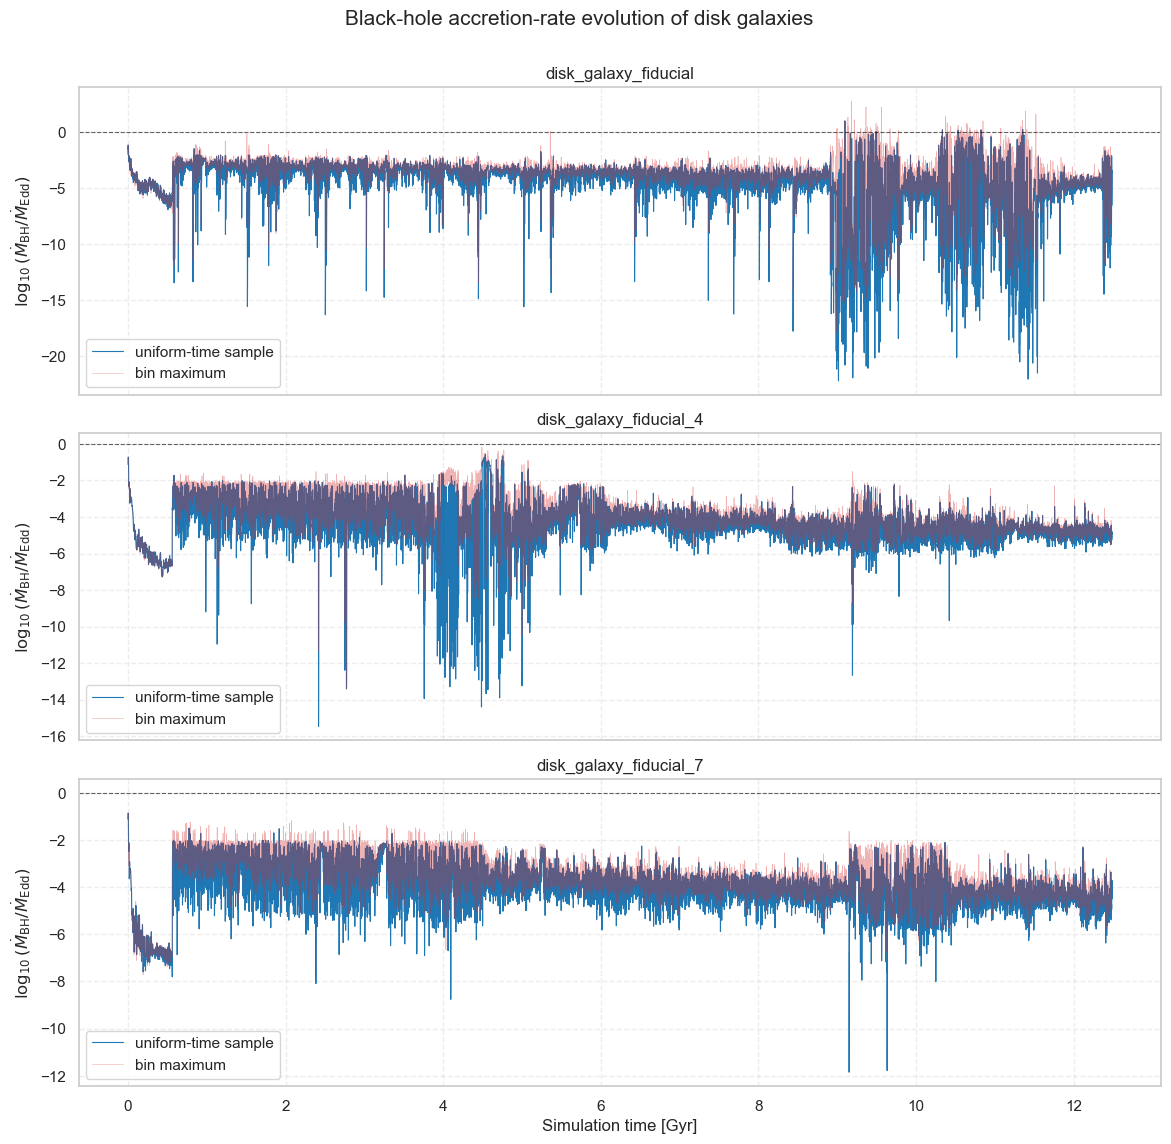

In [5]:
# 单元总注释：像旧 notebook 一样，分别绘制各盘星系的 Eddington 归一化吸积率演化。
galaxy_names = sorted(accretion_series)
fig, axes = plt.subplots(
    nrows=len(galaxy_names),
    ncols=1,
    figsize=(12, max(3.8 * len(galaxy_names), 5.0)),
    sharex=True,
    squeeze=False,
)

for axis, galaxy_name in zip(axes[:, 0], galaxy_names):
    frame = accretion_series[galaxy_name]
    ratio = frame['eddington_ratio'].to_numpy(dtype=np.float64)
    positive = ratio > 0.0
    axis.plot(
        frame.loc[positive, 'time'],
        np.log10(ratio[positive]),
        color='tab:blue',
        linewidth=0.8,
        label='uniform-time sample',
    )
    if SHOW_BIN_MAXIMUM:
        peak = frame['eddington_ratio_bin_max'].to_numpy(dtype=np.float64)
        peak_positive = np.isfinite(peak) & (peak > 0.0)
        axis.plot(
            frame.loc[peak_positive, 'time'],
            np.log10(peak[peak_positive]),
            color='tab:red',
            linewidth=0.45,
            alpha=0.35,
            label='bin maximum',
        )
    axis.axhline(0.0, color='black', linestyle='--', linewidth=0.8, alpha=0.6)
    axis.set_ylabel(r'$\log_{10}(\dot{M}_{\rm BH}/\dot{M}_{\rm Edd})$')
    axis.set_title(galaxy_name)
    axis.grid(True, which='both', linestyle='--', alpha=0.35)
    axis.legend(loc='best')

axes[-1, 0].set_xlabel('Simulation time [Gyr]')
fig.suptitle('Black-hole accretion-rate evolution of disk galaxies', fontsize=15, y=1.002)
fig.tight_layout()
plt.show()

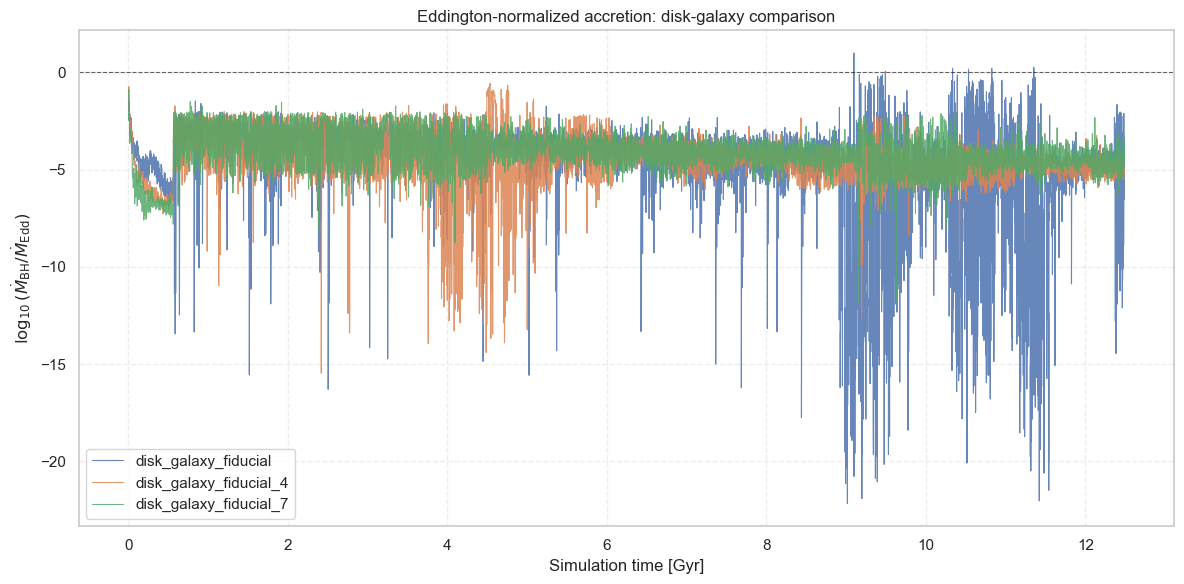

In [6]:
# 单元总注释：在同一坐标系比较所有盘星系的 Eddington 归一化吸积率。
fig, axis = plt.subplots(figsize=(12, 6))

for galaxy_name, frame in accretion_series.items():
    ratio = frame['eddington_ratio'].to_numpy(dtype=np.float64)
    positive = ratio > 0.0
    axis.plot(
        frame.loc[positive, 'time'],
        np.log10(ratio[positive]),
        linewidth=0.8,
        alpha=0.85,
        label=galaxy_name,
    )

axis.axhline(0.0, color='black', linestyle='--', linewidth=0.8, alpha=0.6)
axis.set_xlabel('Simulation time [Gyr]')
axis.set_ylabel(r'$\log_{10}(\dot{M}_{\rm BH}/\dot{M}_{\rm Edd})$')
axis.set_title('Eddington-normalized accretion: disk-galaxy comparison')
axis.grid(True, which='both', linestyle='--', alpha=0.35)
axis.legend(loc='best')
fig.tight_layout()
plt.show()

In [ ]:
# 单元总注释：绘制未除以 Eddington 极限的实际 mdot_bh，便于后续直接与瞬时 SFR 比较。
fig, axis = plt.subplots(figsize=(12, 6))

for galaxy_name, frame in accretion_series.items():
    line, = axis.plot(
        frame['time'],
        frame['mdot_bh'],
        linewidth=0.8,
        alpha=0.85,
        label=galaxy_name,
    )
    if SHOW_BIN_MAXIMUM:
        peak = frame['mdot_bh_bin_max'].to_numpy(dtype=np.float64)
        peak_valid = np.isfinite(peak)
        axis.plot(
            frame.loc[peak_valid, 'time'],
            peak[peak_valid],
            color=line.get_color(),
            linewidth=0.45,
            alpha=0.25,
        )

axis.set_yscale('symlog', linthresh=MDOT_SYMLOG_LINTHRESH, linscale=0.6)
axis.set_xlabel('Simulation time [Gyr]')
axis.set_ylabel(r'$\dot{M}_{\rm BH}$ [MACER mass code / Gyr]')
axis.set_title('Unnormalized black-hole accretion-rate evolution')
axis.grid(True, which='both', linestyle='--', alpha=0.35)
axis.legend(loc='best')
fig.tight_layout()
plt.show()